# 🌸 Iris Flower Classification
**Oasis Infobyte SIP · Data Science · Task 1**

**Objective:** Train machine learning models that predict the species of an iris flower (*Setosa*, *Versicolor*, *Virginica*) from its sepal and petal measurements.

**Workflow:** Load data → EDA → Visualisation → Feature discussion → Train/test split → Train models → Evaluate → Pick best model

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
import warnings; warnings.filterwarnings("ignore")

## 1. Load the Dataset
The Iris dataset ships with scikit-learn, so no download is needed.

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "target"]
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df.head()

,sepal_length,sepal_width,petal_length,petal_width,target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 2. Exploratory Data Analysis (EDA)

In [3]:
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nNull values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Shape: (150, 6)

Data types:
 sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
target            int64
species             str
dtype: object

Null values per column:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
target          0
species         0
dtype: int64

Duplicate rows: 1


In [4]:
df.drop(columns="target").describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [5]:
df["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

**Observations**
- 150 rows, 4 numeric features, 3 species with 50 samples each (perfectly balanced).
- There are no missing values, so no imputation is needed.
- Any duplicate rows are few and harmless for this tiny dataset.

## 3. Visualisations

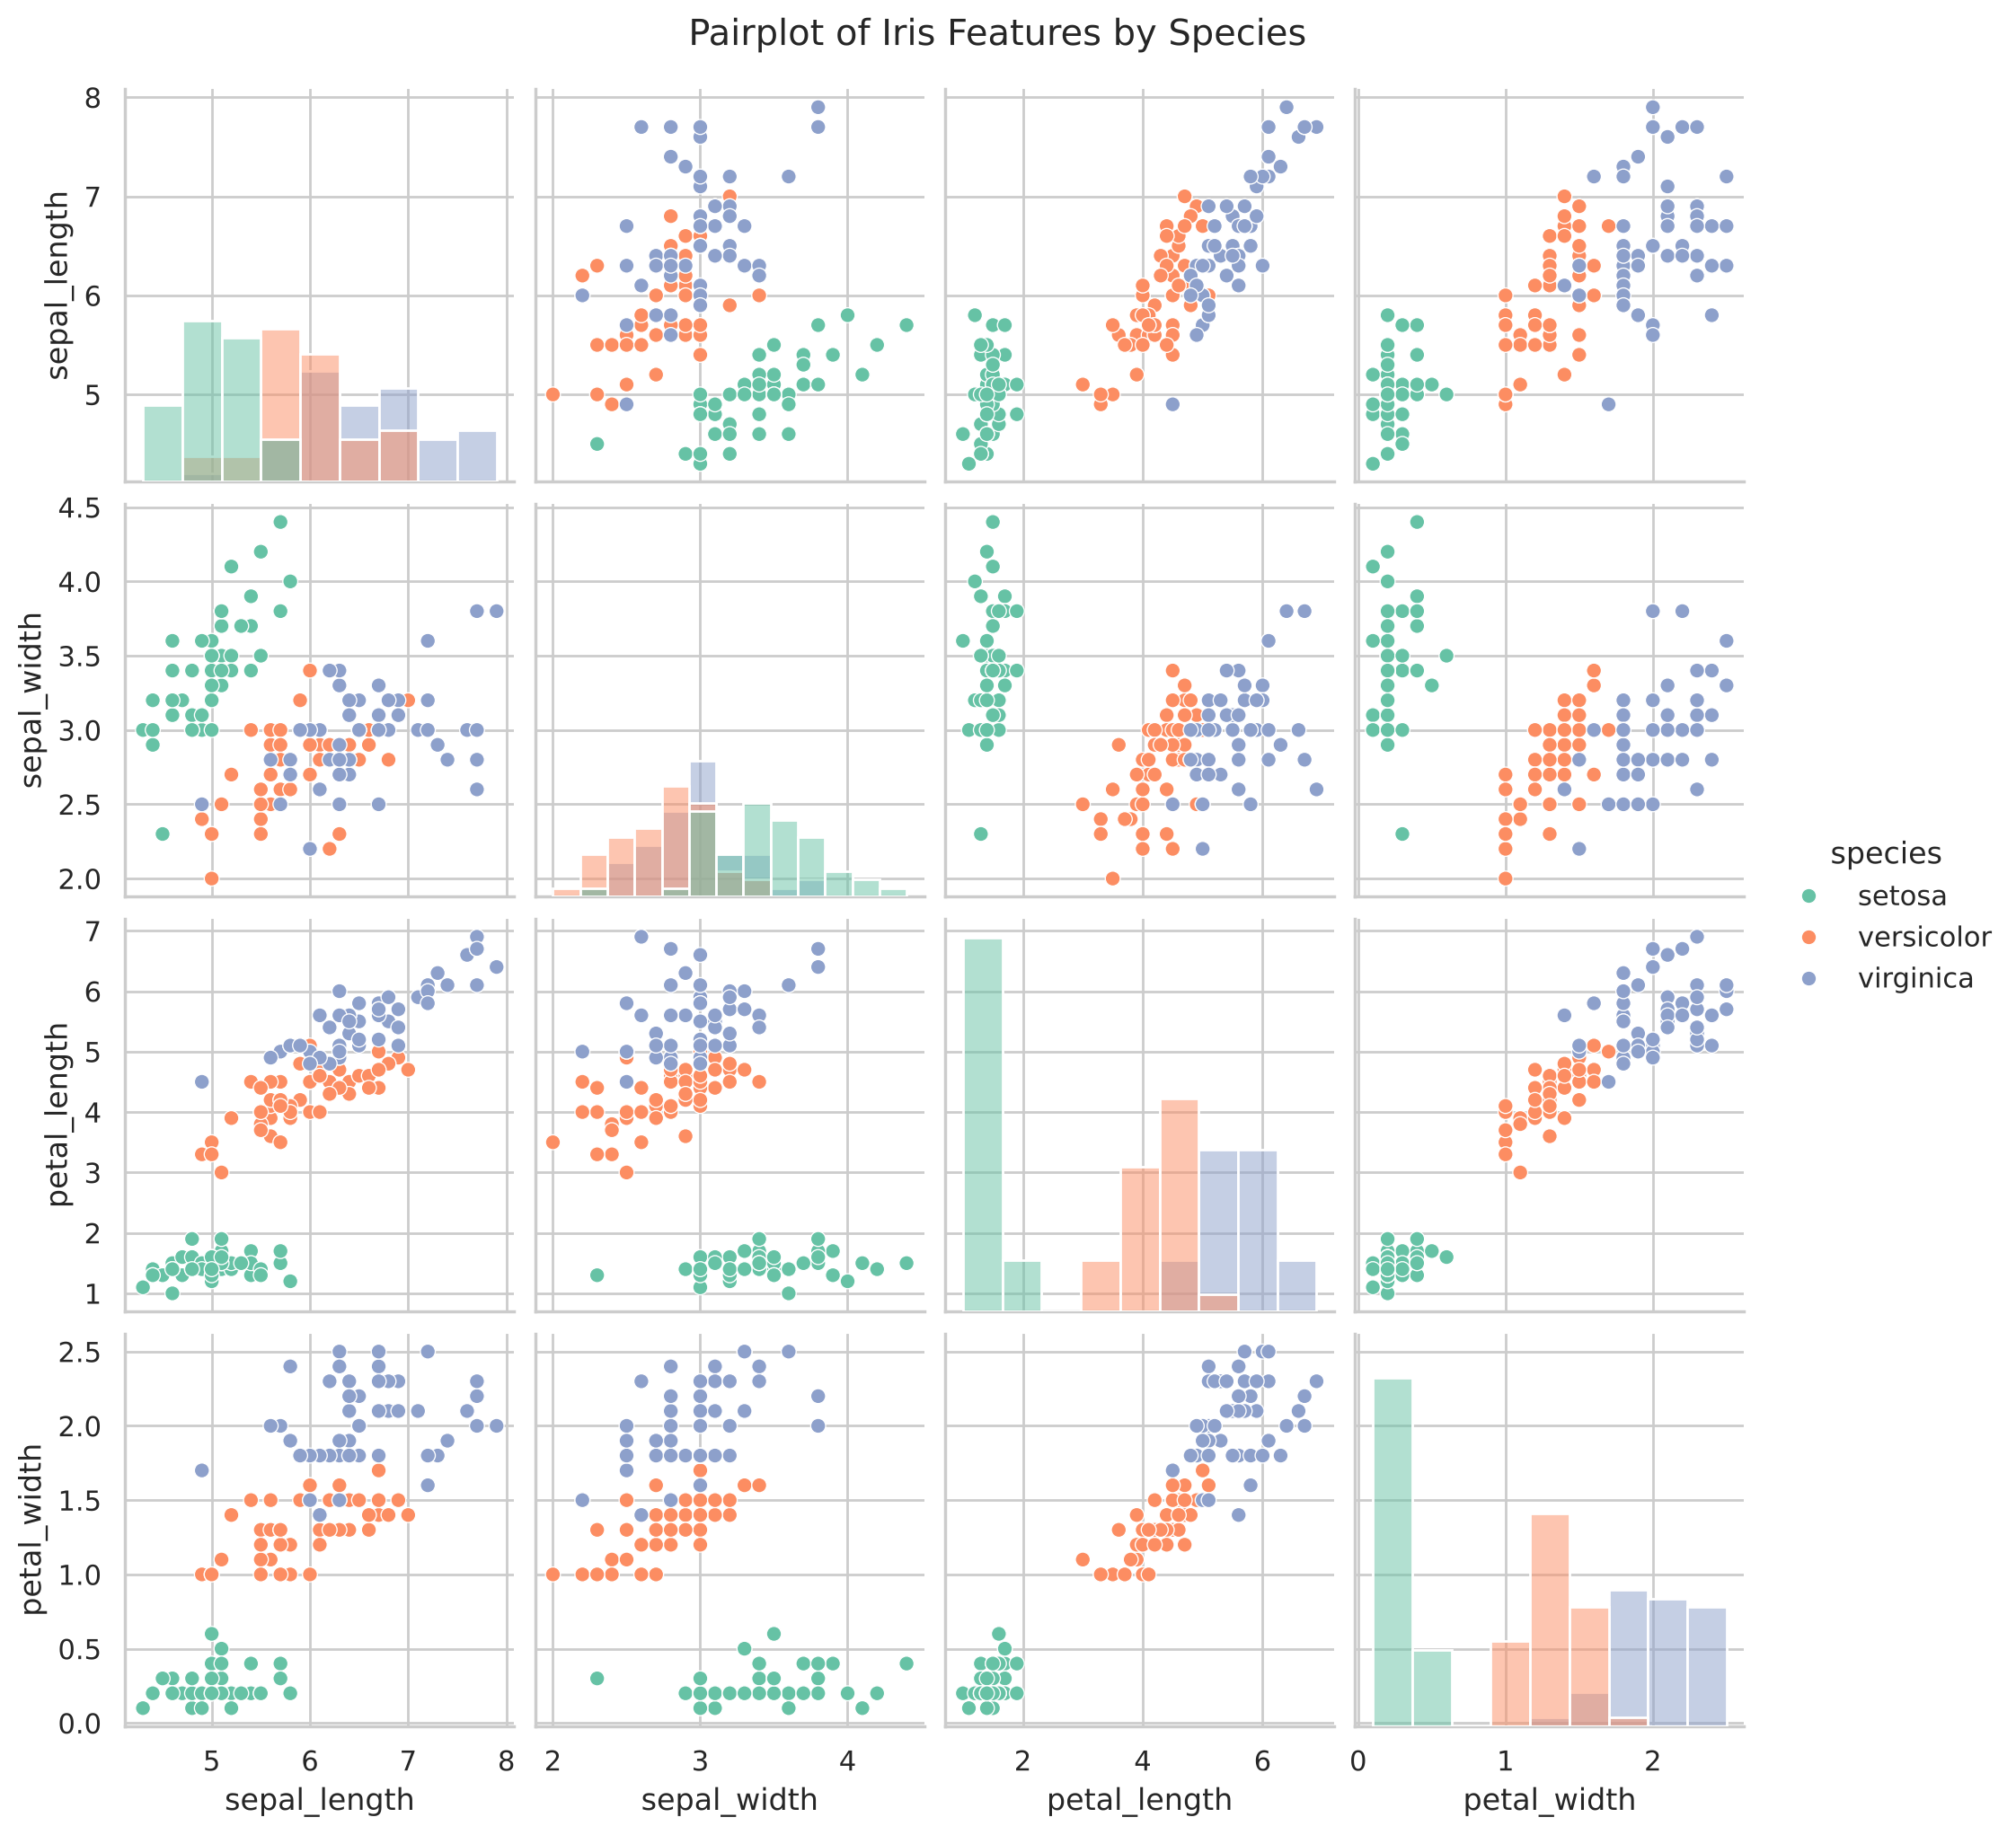

In [6]:
sns.pairplot(df.drop(columns="target"), hue="species", palette="Set2", diag_kind="hist")
plt.suptitle("Pairplot of Iris Features by Species", y=1.02)
plt.show()

**Observation:** Setosa is clearly separated from the other two species, especially in petal length and petal width. Versicolor and Virginica overlap a little.

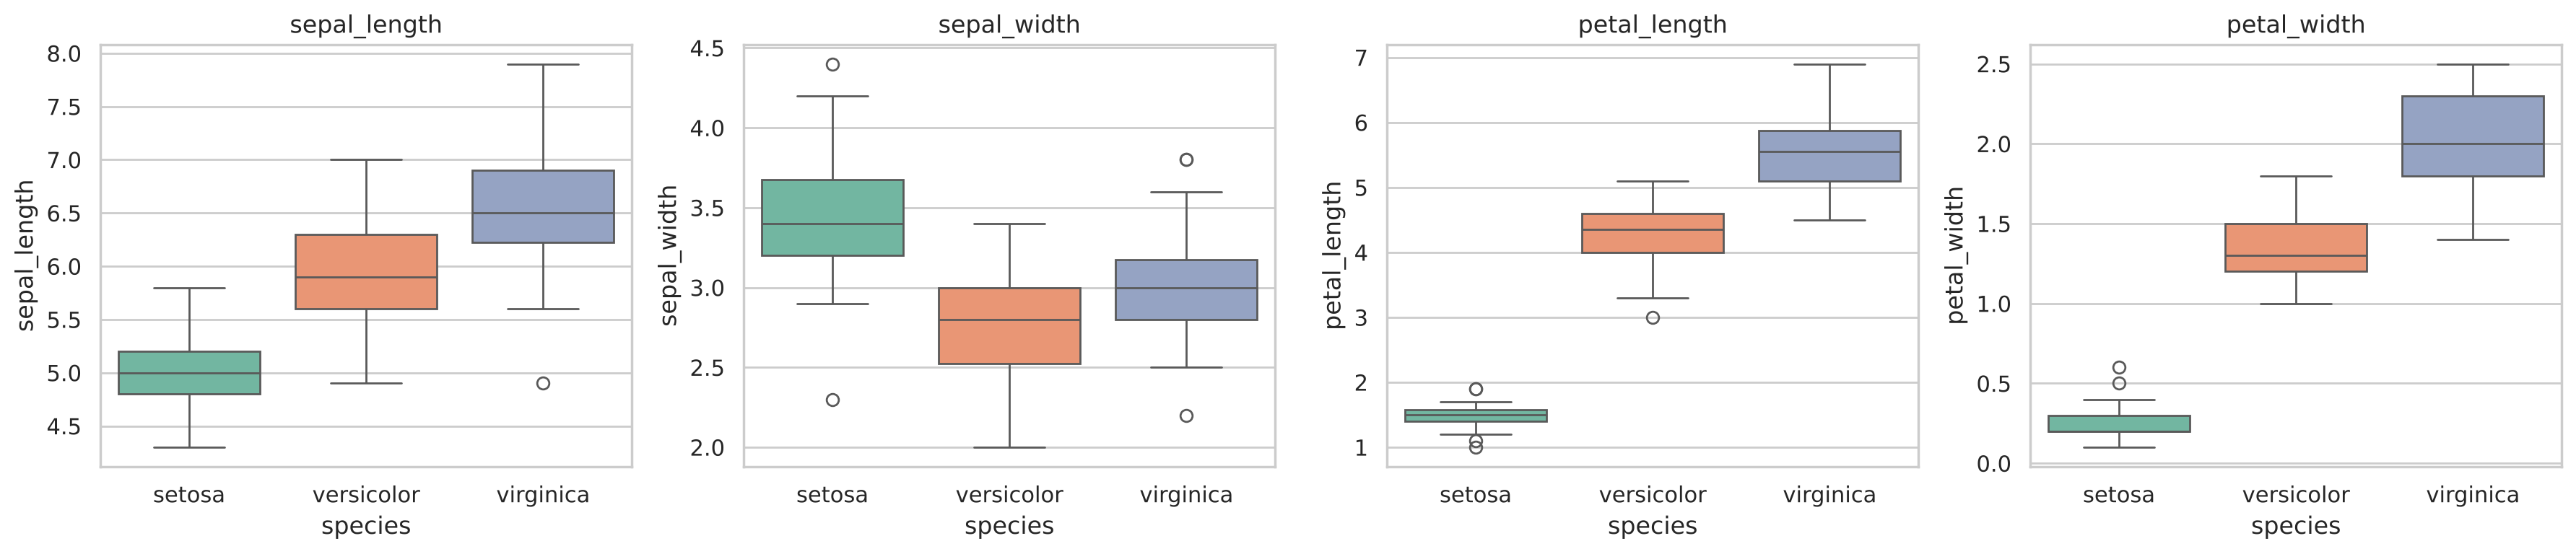

In [7]:
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, f in zip(axes, features):
    sns.boxplot(data=df, x="species", y=f, palette="Set2", ax=ax)
    ax.set_title(f)
plt.tight_layout(); plt.show()

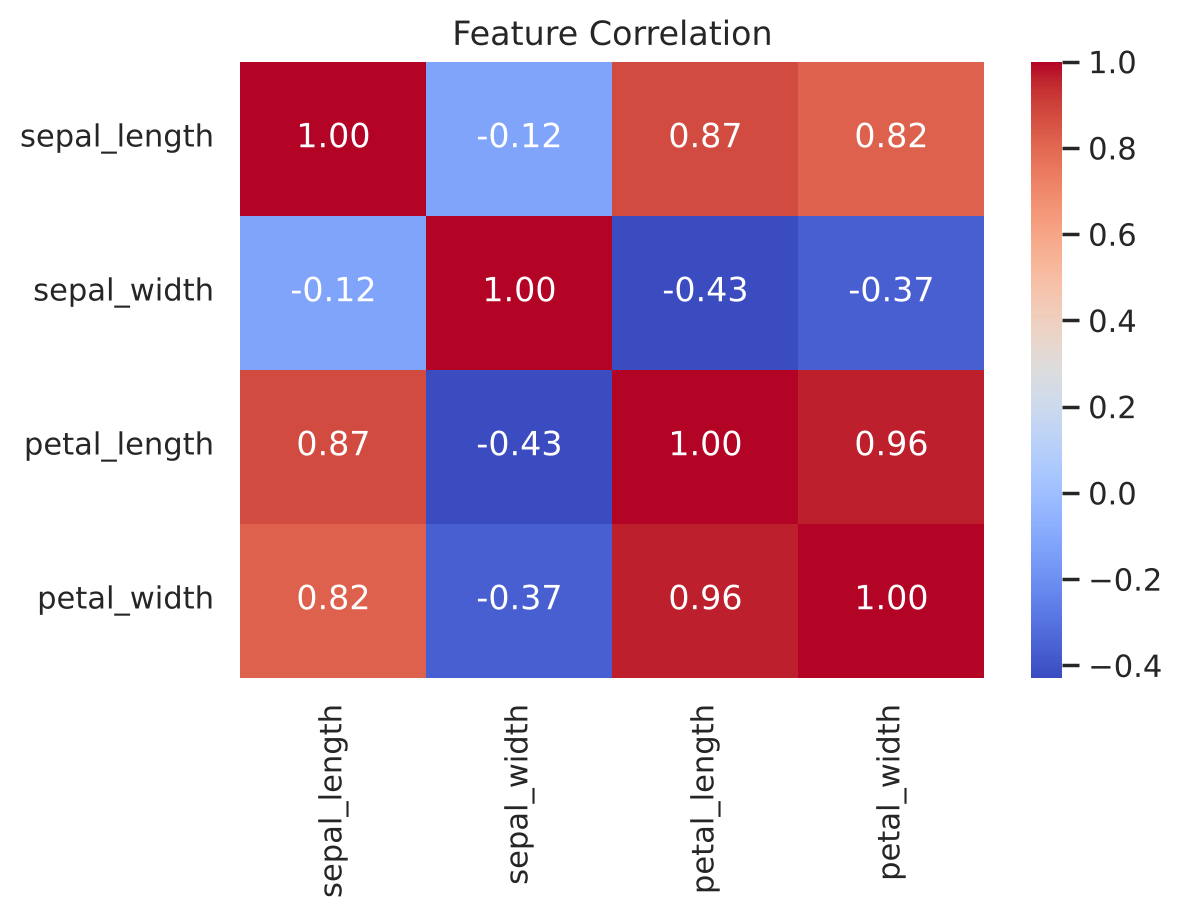

In [8]:
plt.figure(figsize=(6, 4))
sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation"); plt.show()

## 4. Feature Selection Discussion

In [9]:
# Rank features by how much they vary between species relative to within-species spread (F-statistic)
from sklearn.feature_selection import f_classif
f_vals, _ = f_classif(df[features], df["target"])
pd.Series(f_vals, index=features).sort_values(ascending=False).round(1)

petal_length    1180.2
petal_width      960.0
sepal_length     119.3
sepal_width       49.2
dtype: float64

**Which features are most discriminative?**
- **Petal length** and **petal width** have the highest F-scores. The box plots show almost no overlap between Setosa and the other classes, and only a small overlap between Versicolor and Virginica.
- **Sepal length** is moderately useful.
- **Sepal width** is the weakest, since all three species overlap heavily on it.
- Petal length and petal width are strongly correlated with each other, so one of them partly carries the other's information.

## 5. Train / Test Split (80/20)

In [10]:
X = df[features]
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)   # stratify keeps class balance
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (120, 4)  Test: (30, 4)


## 6. Train Models
We train four classifiers (the task needs at least two).

In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "K-Nearest Neighbours": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}
preds = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    preds[name] = m.predict(X_test)
print("All models trained.")

All models trained.


## 7. Evaluate Each Model

In [12]:
results = []
for name, p in preds.items():
    acc = accuracy_score(y_test, p)
    results.append((name, acc))
    print("=" * 60)
    print(f"{name}  |  Accuracy: {acc:.4f}")
    print("=" * 60)
    print(classification_report(y_test, p, target_names=iris.target_names))

Logistic Regression  |  Accuracy: 0.9667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



K-Nearest Neighbours  |  Accuracy: 1.0000
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Decision Tree  |  Accuracy: 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Random Forest  |  Accuracy: 0.9000
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor     

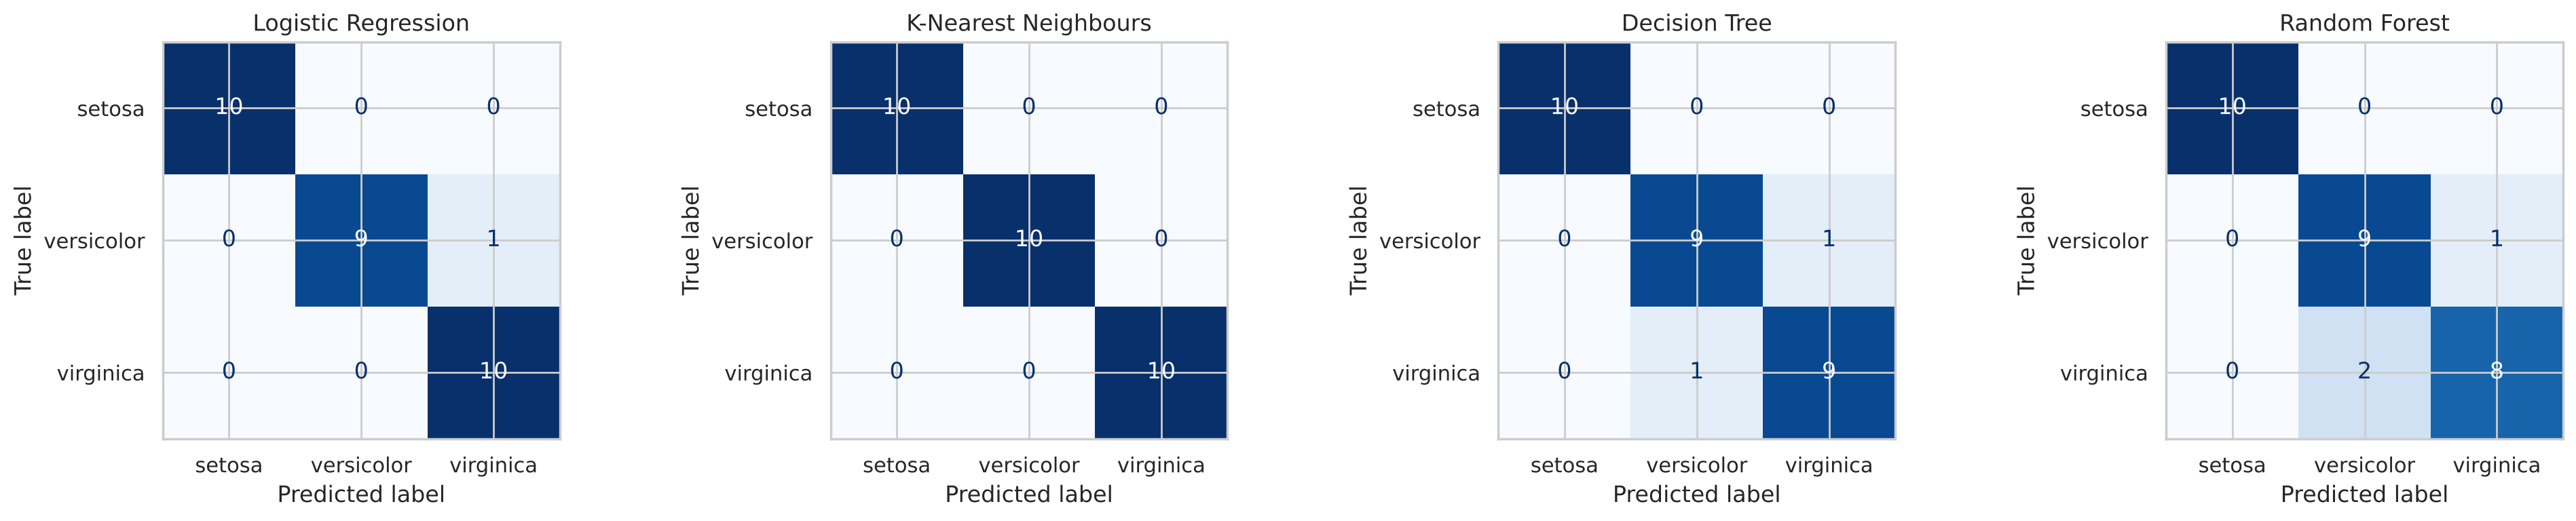

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=iris.target_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 8. Compare Models and Choose the Best

In [14]:
from sklearn.model_selection import cross_val_score
cv = {n: cross_val_score(m, X, y, cv=5).mean() for n, m in models.items()}
summary = pd.DataFrame({
    "Test Accuracy": dict(results),
    "5-Fold CV Accuracy": cv
}).round(4).sort_values("5-Fold CV Accuracy", ascending=False)
summary

,Test Accuracy,5-Fold CV Accuracy
Logistic Regression,0.9667,0.9733
K-Nearest Neighbours,1.0000,0.9733
Random Forest,0.9000,0.9667
Decision Tree,0.9333,0.9533


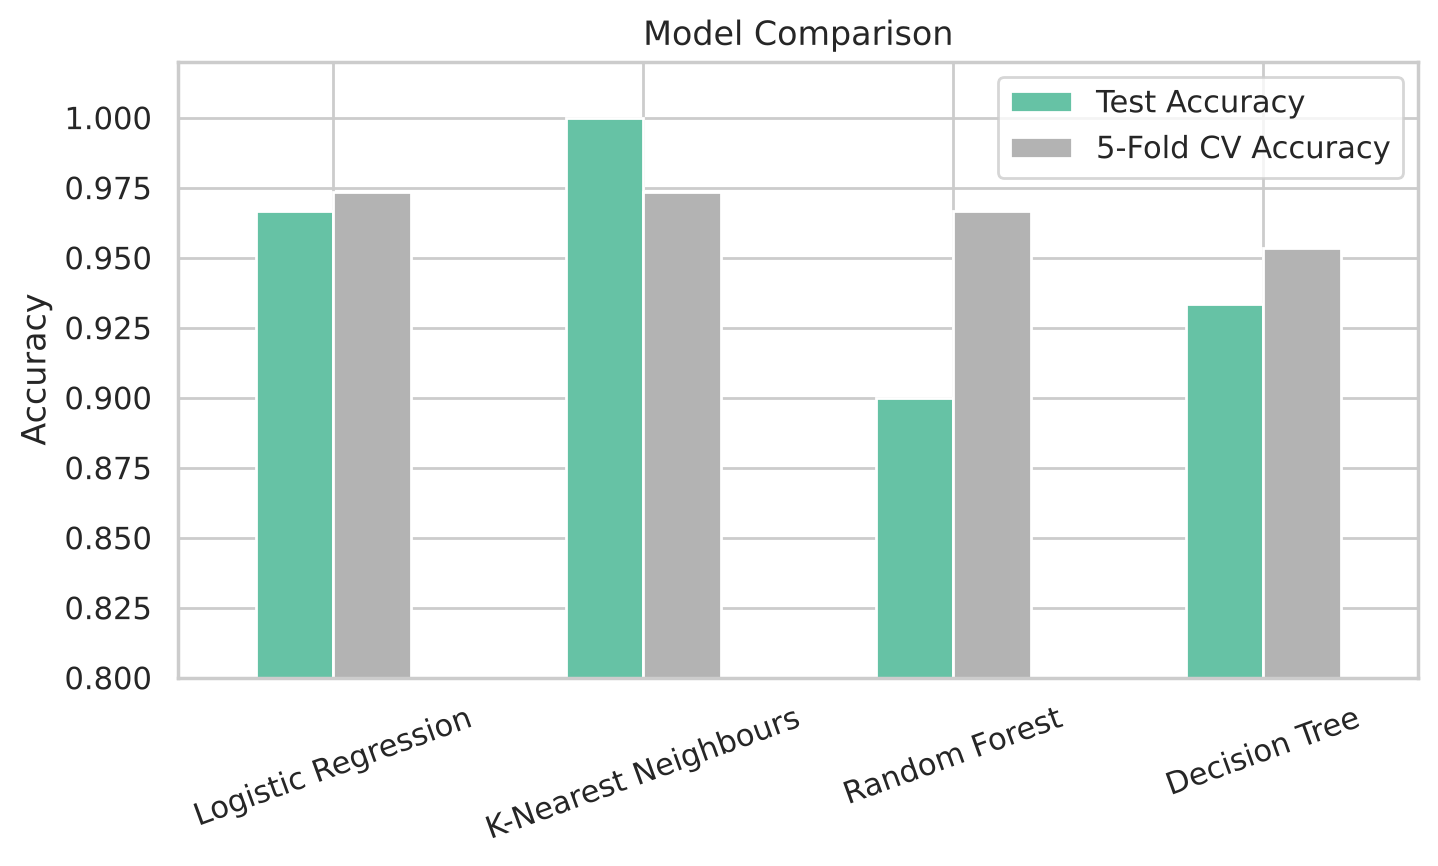

In [15]:
summary.plot(kind="bar", figsize=(8, 4), ylim=(0.8, 1.02), colormap="Set2")
plt.title("Model Comparison"); plt.ylabel("Accuracy"); plt.xticks(rotation=20); plt.show()

## 9. Conclusion
- All four models perform well (**90–100% test accuracy, 95–97% cross-validated**). The classes are almost linearly separable, mostly because of the petal measurements.
- **Best model: K-Nearest Neighbours.** It scored 100% on the test set and tied Logistic Regression for the top 5-fold CV accuracy (97.3%). Logistic Regression is an equally good choice and is simpler and faster to run.
- Setosa is classified perfectly by every model, and the few mistakes are between Versicolor and Virginica.
- With only 30 test samples, one wrong prediction changes accuracy by ~3.3%, so the test-split ranking is noisy. That is why 5-fold cross-validation is shown alongside it, and why Random Forest's lower test score does not mean it is a worse model.